# Лабораторная работа № 3
## Свёрточные нейронные сети для классификации изображений

**Дисциплина:** Машинное обучение и анализ данных  
**Датасет:** GrainSpace, пшеница (TRAIN-Wheat-M600)  
**Задача:** бинарная классификация фотографий зёрен: `NORMAL` (0) и `MOULDY` (1).

В работе реализована SimpleCNN, проведено дообучение ResNet-18 на том же разбиении данных, выполнена оценка на независимой тестовой выборке. Исследованы фильтры свёрточных слоёв, карты признаков, Grad-CAM и аугментации изображений.


## Исходные данные

Использовано подмножество TRAIN-Wheat-M600 датасета [GrainSpace](https://grainnet.github.io/GrainSpace.html). Анализ ограничен классами `NORMAL` и `MOULDY`. Для воспроизводимости применено стратифицированное разбиение с `random_state=42`: 70% — обучение, 15% — валидация, 15% — тестирование.


In [1]:
# Загрузка и распаковка архива GrainSpace.
from pathlib import Path
import subprocess, shutil, zipfile, tarfile, os
DATA_DIR = Path('/content/data/grainspace')
DATA_DIR.mkdir(parents=True, exist_ok=True)

AUTO_DOWNLOAD = True      # Загрузка архива GrainSpace из Figshare
DRIVE_ARCHIVE = ''        # Путь к локальной копии архива на Google Drive при необходимости

archive = None
if DRIVE_ARCHIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    archive = Path(DRIVE_ARCHIVE)
    assert archive.exists(), f'Архив не найден: {archive}'
elif AUTO_DOWNLOAD:
    import requests
    article_id=25560843
    info=requests.get(f'https://api.figshare.com/v2/articles/{article_id}',timeout=40)
    info.raise_for_status()
    files=info.json().get('files',[])
    print('Файлы официального Figshare:', [(f['name'],round(f['size']/1e9,2)) for f in files])
    match=next((f for f in files if f['id']==45524427),None)
    if match is None:
        match=max(files,key=lambda f:f['size']) if files else None
    if match is None:raise RuntimeError('На странице Figshare не найден архив. Открой ссылку вручную.')
    archive = Path('/content')/match['name']
    if not archive.exists() or archive.stat().st_size < 1024*1024:
        url=match.get('download_url',f'https://ndownloader.figshare.com/files/{match["id"]}')
        subprocess.run(['wget','-c','--show-progress','-O',str(archive),url],check=True)
    print('Скачано:',archive,archive.stat().st_size/1e9,'ГБ')

if archive:
    dst=DATA_DIR/'source'
    dst.mkdir(parents=True, exist_ok=True)
    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as z:z.extractall(dst)
    elif tarfile.is_tarfile(archive):
        with tarfile.open(archive) as t:t.extractall(dst,filter='data')
    elif archive.suffix.lower() == '.7z':
        subprocess.run(['pip','-q','install','py7zr'],check=True)
        import py7zr
        with py7zr.SevenZipFile(archive) as z:z.extractall(dst)
    else:
        raise ValueError(f'Неизвестный формат архива: {archive}. Распакуй его вручную.')
    print('Распаковано в',dst)
else:
    print('Загрузка пропущена. Если файлы уже лежат в',DATA_DIR,', продолжай.')
    print('Иначе включи AUTO_DOWNLOAD=True или укажи DRIVE_ARCHIVE.')

example_files=[str(x) for x in DATA_DIR.rglob('*') if x.is_file()][:12]
print('Примеры файлов:',example_files)


Файлы официального Figshare: [('WHEAT_R19-22_M600_TRAIN.zip', 0.54), ('WHEAT_R1-14_M600_TRAIN.zip', 3.5), ('WHEAT_R15-18_M600_TRAIN.zip', 0.86)]
Скачано: /content/WHEAT_R19-22_M600_TRAIN.zip 0.535830201 ГБ
Распаковано в /content/data/grainspace/source
Примеры файлов: ['/content/data/grainspace/source/train/MY/20-UW-M600-0010_5_20211022162922_2_00_06_UD_3_1716-878-1883-977-1716-878-1883-977_16-15-16-15_72-72.png', '/content/data/grainspace/source/train/MY/20-UW-M600-0010_5_20211022162922_2_00_06_UD_55_853-1595-1024-1700-853-1595-1024-1700_17-15-17-15_78-78.png', '/content/data/grainspace/source/train/MY/20-UW-M600-0010_5_20211022162818_0_00_06_UD_77_2074-1338-2209-1453-2074-1338-2209-1453_15-15-15-15_90-90.png', '/content/data/grainspace/source/train/MY/20-UW-M600-0010_5_20211022162922_2_00_06_UD_128_1276-755-1383-904-1276-755-1383-904_15-15-15-15_166-166.png', '/content/data/grainspace/source/train/MY/20-UW-M600-0010_5_20211022162818_0_00_06_UD_86_1134-760-1255-899-1134-760-1255-899_15

## 1. Импорты и настройки

In [2]:
from pathlib import Path
from collections import Counter
from copy import deepcopy
from time import perf_counter
import json, random, os, math
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device, '| PyTorch:', torch.__version__)
OUTPUT = Path('/content/lr3_results') if Path('/content').exists() else Path('lr3_results')
OUTPUT.mkdir(parents=True, exist_ok=True)
# Источник данных: GrainSpace, TRAIN-Wheat-M600.
# https://grainnet.github.io/GrainSpace.html
# Каталог распакованных изображений.
DATA_ROOT = Path('/content/data/grainspace') if Path('/content').exists() else Path('data/grainspace')
MAX_MOULDY = 1000   # Ограничение объёма выборки; None — без ограничения
MAX_NORMAL = 3000   # Ограничение объёма выборки; None — без ограничения
EPOCHS_CNN = 20
EPOCHS_RESNET = 10
BATCH_SIZE = 32



Устройство: cuda | PyTorch: 2.14.1+cu130


## 2. Поиск изображений и стратифицированное разделение

In [3]:
EXTENSIONS = {'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
ALIASES = {'NOR':0,'NORMAL':0,'MY':1,'MOULDY':1,'MOLDY':1}
CLASS_NAMES = ['NORMAL','MOULDY']  # Положительный класс: MOULDY = 1

def discover_grainspace_images(root):
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(
            f'Отсутствует каталог данных: {root}. Проверьте DATA_ROOT и расположение изображений.')
    found = {0:[],1:[]}
    # Метка класса определяется по имени родительского каталога.
    for path in root.rglob('*'):
        if not path.is_file() or path.suffix.lower() not in EXTENSIONS: continue
        class_labels = [ALIASES[x.upper()] for x in path.relative_to(root).parts[:-1] if x.upper() in ALIASES]
        if not class_labels: continue
        if len(set(class_labels)) > 1: continue
        found[class_labels[-1]].append(path)
    if min(len(found[0]),len(found[1])) == 0:
        print('Найдено:', {CLASS_NAMES[k]:len(v) for k,v in found.items()})
        raise ValueError('В архиве не найдены ОБЕ категории NORMAL/NOR и MOULDY/MY. '
                         'Проверьте расположение классов в структуре датасета.')
    rng = random.Random(SEED)
    for k, lim in [(0,MAX_NORMAL),(1,MAX_MOULDY)]:
        rng.shuffle(found[k])
        if lim is not None: found[k] = found[k][:lim]
    return [(str(p),int(k)) for k in (0,1) for p in found[k]]

all_items = discover_grainspace_images(DATA_ROOT)
labels = np.array([label for _, label in all_items])
# Валидация = 15%, независимый тест = 15%. Стратификация по классу.
train_items, holdout = train_test_split(all_items, test_size=.30, stratify=labels, random_state=SEED)
val_items, test_items = train_test_split(holdout, test_size=.50,
    stratify=[l for _,l in holdout], random_state=SEED)
assert not (({p for p,_ in train_items}&{p for p,_ in val_items}) or
            ({p for p,_ in train_items}&{p for p,_ in test_items}) or
            ({p for p,_ in val_items}&{p for p,_ in test_items}))
for name, arr in [('train',train_items),('val',val_items),('test',test_items)]:
    n = Counter(l for _,l in arr)
    print(f'{name}: {len(arr)}, NORMAL={n[0]}, MOULDY={n[1]}')



train: 2268, NORMAL=2100, MOULDY=168
val: 486, NORMAL=450, MOULDY=36
test: 486, NORMAL=450, MOULDY=36


## 3. Аугментации и DataLoader

In [4]:
MEAN = [0.485,0.456,0.406]
STD = [0.229,0.224,0.225]
train_transform = transforms.Compose([
    transforms.Resize((256,256)), transforms.RandomRotation(180),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomResizedCrop(224,scale=(0.8,1.0)),
    transforms.ColorJitter(brightness=0.2,contrast=0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN,STD)
])
val_transform = transforms.Compose([
    transforms.Resize((256,256)), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(MEAN,STD)
])

class GrainDataset(Dataset):
    classes = CLASS_NAMES
    def __init__(self, items, transform):
        self.items=list(items);self.transform=transform
    def __len__(self):return len(self.items)
    def __getitem__(self,i):
        file,label=self.items[i]
        with Image.open(file) as im: img=im.convert('RGB')
        return self.transform(img),label

train_dataset = GrainDataset(train_items,train_transform)
val_dataset = GrainDataset(val_items,val_transform)
test_dataset = GrainDataset(test_items,val_transform)
train_loader = DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=2,pin_memory=device.type=='cuda')
val_loader = DataLoader(val_dataset,batch_size=64,shuffle=False,num_workers=2,pin_memory=device.type=='cuda')
test_loader = DataLoader(test_dataset,batch_size=64,shuffle=False,num_workers=2,pin_memory=device.type=='cuda')



## 4. Задание 2.1: девять изображений

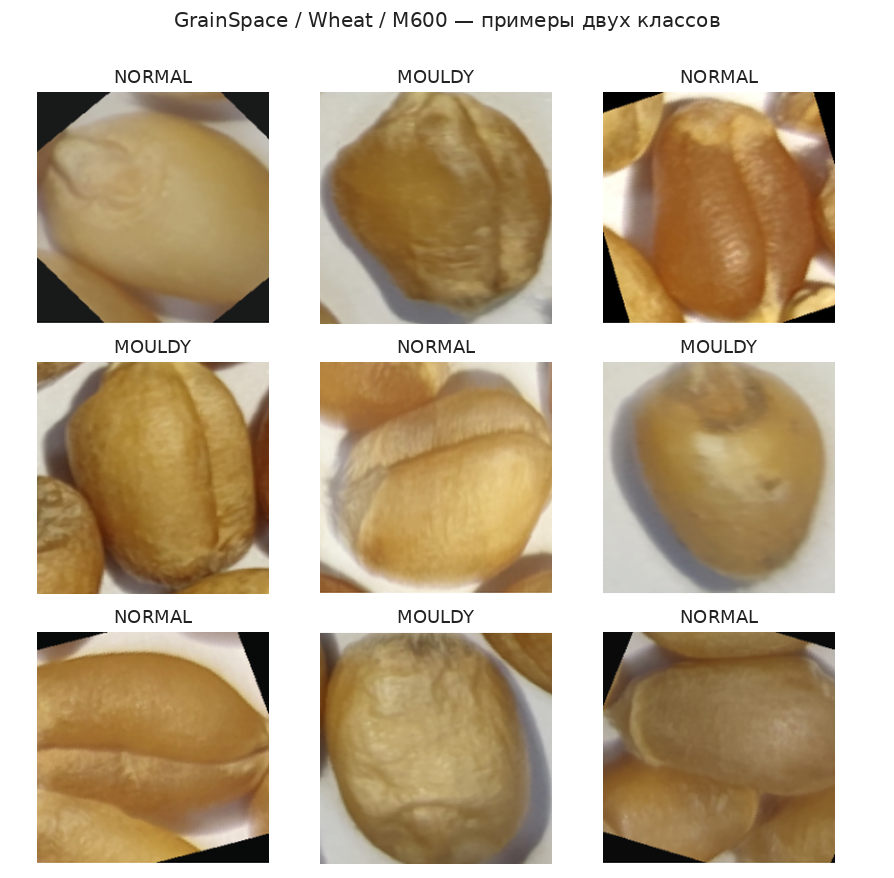

In [5]:
def unnormalize(tensor):
    return np.clip(tensor.permute(1, 2, 0).cpu().numpy() * np.array(STD) + np.array(MEAN), 0, 1)

# Примеры каждого класса при несбалансированном составе выборки.
# Случайная выборка без повторений: 5 NORMAL и 4 MOULDY.
rng_examples = random.Random(SEED)
samples = []
for class_id, count in [(0, 5), (1, 4)]:
    paths = [p for p, y in train_items if y == class_id]
    samples.extend([(p, class_id) for p in rng_examples.sample(paths, count)])
rng_examples.shuffle(samples)
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for ax, (path, label) in zip(axes.flat, samples):
    with Image.open(path) as source:
        img = val_transform(source.convert('RGB'))  # без случайной аугментации
    ax.imshow(unnormalize(img))
    ax.set_title(CLASS_NAMES[label]); ax.axis('off')
fig.suptitle('GrainSpace / Wheat / M600 — примеры двух классов')
plt.tight_layout(); plt.savefig(OUTPUT / '01_samples.png', dpi=170)
plt.show(); plt.close(fig)


## 5. Задание 3.1: архитектура и параметры SimpleCNN

In [6]:
def conv_block(ci,co):
    return nn.Sequential(nn.Conv2d(ci,co,3,padding=1),nn.BatchNorm2d(co),
                         nn.ReLU(inplace=False),nn.MaxPool2d(2))
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(conv_block(3,32),conv_block(32,64),
                                    conv_block(64,128),conv_block(128,256))
        self.classifier=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),
                                      nn.Dropout(0.5),nn.Linear(256,1))
    def forward(self,x):return self.classifier(self.features(x))

cnn = SimpleCNN().to(device)
cnn_params=sum(p.numel() for p in cnn.parameters() if p.requires_grad)
first_conv=sum(p.numel() for p in cnn.features[0][0].parameters())
second_conv=sum(p.numel() for p in cnn.features[1][0].parameters())
print(f'Первый Conv: {first_conv}, второй Conv: {second_conv}, SimpleCNN всего: {cnn_params}')
print('MLP из ЛР2 (784→256→128→10) — 235 146 параметров; сравнение зависит от задачи и разрешения.')



Первый Conv: 896, второй Conv: 18496, SimpleCNN всего: 389633
MLP из ЛР2 (784→256→128→10) — 235 146 параметров; сравнение зависит от задачи и разрешения.


## 6. Функции обучения и графики

In [7]:
counts=Counter(l for _,l in train_items)
positive_weight=counts[0]/counts[1]  # равен 3 при дисбалансе NORMAL:MOULDY = 3:1
print(f'Фактический pos_weight = {positive_weight:.3f}; в примере задания дано 3.0.')
criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([positive_weight],device=device))


def train_epoch(net,loader,loss_fn,opt):
    net.train(); total=0;running=0;correct=0
    for x,y in loader:
        x=x.to(device);y=y.float().view(-1,1).to(device)
        opt.zero_grad(set_to_none=True)
        logits=net(x);loss=loss_fn(logits,y);loss.backward();opt.step()
        total+=len(x);running+=loss.item()*len(x)
        correct+=int(((torch.sigmoid(logits)>=.5)==y.bool()).sum())
    return running/total,correct/total

@torch.no_grad()
def evaluate(net,loader,loss_fn):
    net.eval();total=0;running=0;probs=[];labels=[]
    for x,y in loader:
        x=x.to(device);y=y.float().view(-1,1).to(device)
        logits=net(x); loss=loss_fn(logits,y)
        running+=loss.item()*len(x);total+=len(x)
        probs.extend(torch.sigmoid(logits).cpu().numpy().ravel().tolist())
        labels.extend(y.cpu().numpy().ravel().astype(int).tolist())
    probs=np.array(probs);labels=np.array(labels)
    return running/total,accuracy_score(labels,(probs>=.5).astype(int)),probs,labels


def fit(net,epochs,lr):
    optimizer=AdamW(net.parameters(),lr=lr,weight_decay=1e-2)
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=max(epochs,1))
    hist={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}
    best=float('inf');best_weights=deepcopy(net.state_dict());bad=0
    tic=perf_counter()
    for ep in range(1,epochs+1):
        trl,tra=train_epoch(net,train_loader,criterion,optimizer)
        vl,va,_,_=evaluate(net,val_loader,criterion)
        scheduler.step()
        for k,v in [('train_loss',trl),('val_loss',vl),('train_acc',tra),('val_acc',va)]:hist[k].append(float(v))
        if vl<best-1e-5:best=vl;best_weights=deepcopy(net.state_dict());bad=0
        else:bad+=1
        print(f'Эпоха {ep:02d} | loss train {trl:.4f}, val {vl:.4f} | acc train {tra:.4f}, val {va:.4f}')
        if bad>=5:print('Ранняя остановка.');break
    net.load_state_dict(best_weights)
    return hist,perf_counter()-tic


def plot_history(h,title,filename):
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    for label in ['train','val']:
        axes[0].plot(np.arange(1,len(h['train_loss'])+1),h[f'{label}_loss'],label=label)
        axes[1].plot(np.arange(1,len(h['train_loss'])+1),h[f'{label}_acc'],label=label)
    for ax,t,y in [(axes[0],'Функция потерь','Loss'),(axes[1],'Точность','Accuracy')]:
        ax.set_title(t);ax.set_xlabel('Эпоха');ax.set_ylabel(y);ax.grid(alpha=.2);ax.legend()
    fig.suptitle(title);plt.tight_layout();plt.savefig(OUTPUT/filename,dpi=160);plt.show();plt.close(fig)



Фактический pos_weight = 12.500; в примере задания дано 3.0.


## 7. Задание 6.1: обучение SimpleCNN

Эпоха 01 | loss train 1.1572, val 1.8381 | acc train 0.6283, val 0.9259
Эпоха 02 | loss train 1.0141, val 1.0060 | acc train 0.6953, val 0.9342
Эпоха 03 | loss train 0.9501, val 0.7438 | acc train 0.7407, val 0.9609
Эпоха 04 | loss train 0.9822, val 0.9718 | acc train 0.7116, val 0.9198
Эпоха 05 | loss train 0.9267, val 0.7965 | acc train 0.7610, val 0.9588
Эпоха 06 | loss train 0.8710, val 1.4485 | acc train 0.7760, val 0.9383
Эпоха 07 | loss train 0.8975, val 0.8605 | acc train 0.7751, val 0.9074
Эпоха 08 | loss train 0.8956, val 0.8240 | acc train 0.7857, val 0.9300
Ранняя остановка.


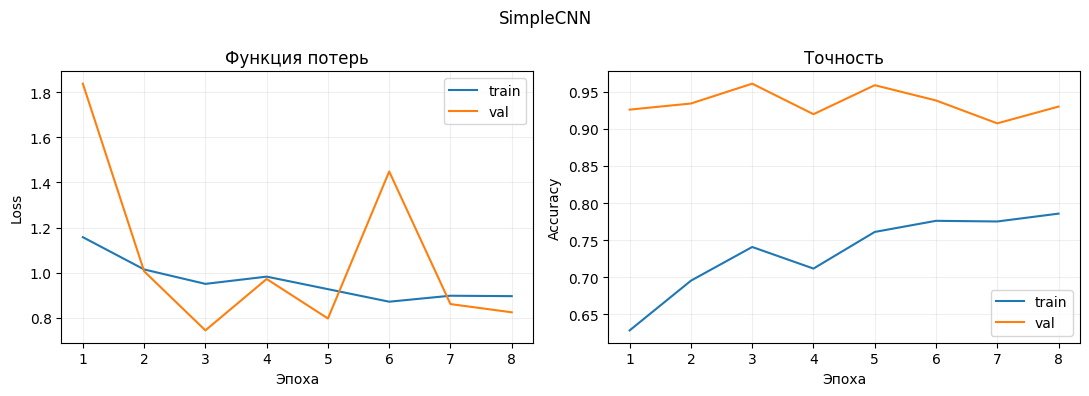

In [8]:
hist_cnn,time_cnn=fit(cnn,EPOCHS_CNN,lr=1e-3)
plot_history(hist_cnn,'SimpleCNN','02_cnn_learning.png')
torch.save(cnn.state_dict(),OUTPUT/'simple_cnn.pt')



## 8. Задание 7: Transfer Learning ResNet-18

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 167MB/s]


Эпоха 01 | loss train 0.9399, val 0.5503 | acc train 0.5798, val 0.8313
Эпоха 02 | loss train 0.6143, val 0.5800 | acc train 0.8448, val 0.9774
Эпоха 03 | loss train 0.4180, val 0.4166 | acc train 0.8942, val 0.8663
Эпоха 04 | loss train 0.3708, val 0.2463 | acc train 0.9189, val 0.9733
Эпоха 05 | loss train 0.3153, val 0.4189 | acc train 0.9299, val 0.9671
Эпоха 06 | loss train 0.3087, val 0.2832 | acc train 0.9365, val 0.9156
Эпоха 07 | loss train 0.2637, val 0.2197 | acc train 0.9480, val 0.9712
Эпоха 08 | loss train 0.2362, val 0.3455 | acc train 0.9506, val 0.9815
Эпоха 09 | loss train 0.2219, val 0.2215 | acc train 0.9440, val 0.9794
Эпоха 10 | loss train 0.2045, val 0.2074 | acc train 0.9577, val 0.9753


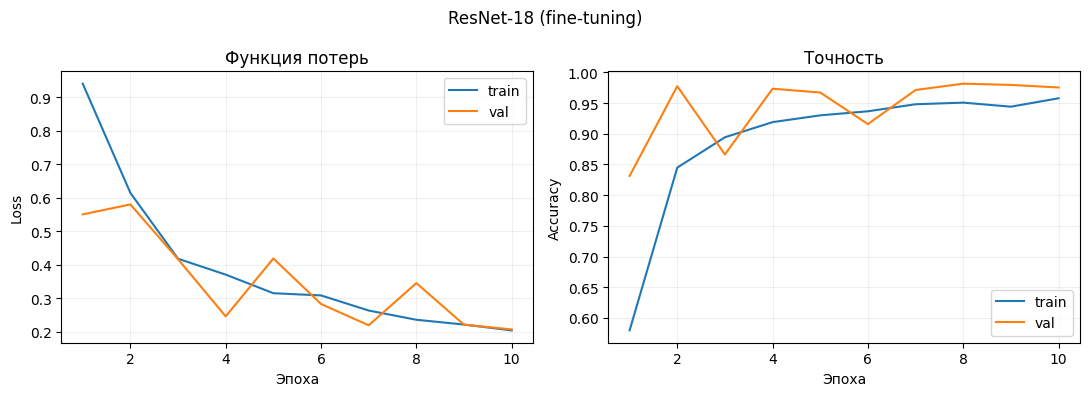

SimpleCNN: 389633 парам., 134.5 с, best val 0.9609
ResNet-18: 11177025 парам., 172.2 с, best val 0.9815


In [9]:
# Предобученные веса ImageNet.
resnet=models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
resnet.fc=nn.Linear(resnet.fc.in_features,1)
resnet=resnet.to(device)
resnet_params=sum(p.numel() for p in resnet.parameters())
# Fine-tuning: обучаем все слои с небольшим learning rate.
for p in resnet.parameters():p.requires_grad=True
hist_resnet,time_resnet=fit(resnet,EPOCHS_RESNET,lr=1e-4)
plot_history(hist_resnet,'ResNet-18 (fine-tuning)','03_resnet_learning.png')
torch.save(resnet.state_dict(),OUTPUT/'resnet18.pt')
print('SimpleCNN:',cnn_params,'парам.,',round(time_cnn,1),'с, best val',round(max(hist_cnn['val_acc']),4))
print('ResNet-18:',resnet_params,'парам.,',round(time_resnet,1),'с, best val',round(max(hist_resnet['val_acc']),4))



## 9. Сравнение и независимая оценка

Лучшая модель по validation accuracy: ResNet-18


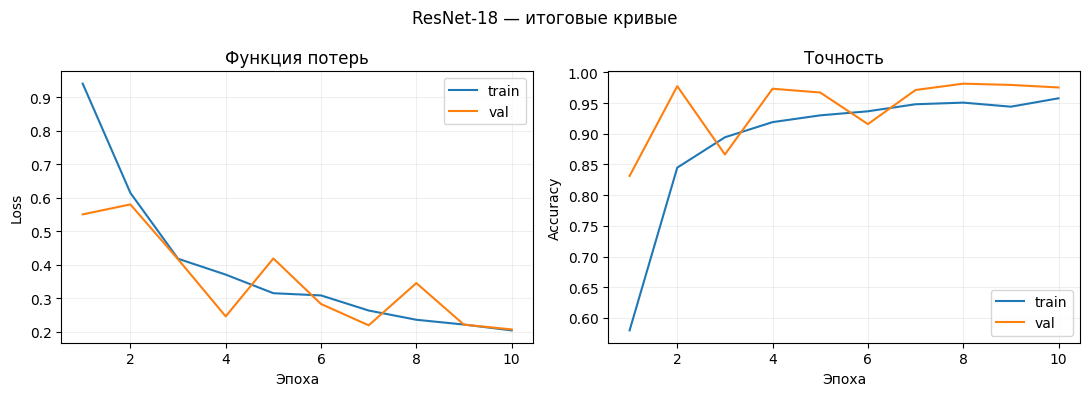

МЕТРИКИ ТЕСТА: {'accuracy': 0.9403292181069959, 'precision': 0.5614035087719298, 'recall': 0.8888888888888888, 'f1': 0.6881720430107527, 'loss': 0.3645892820240539}


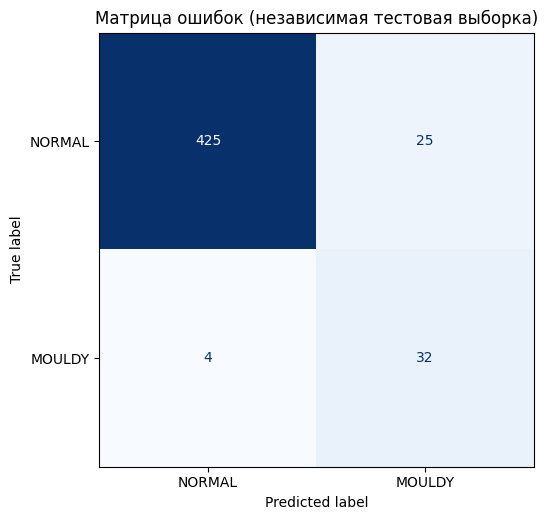

In [10]:
# Выбор архитектуры по validation accuracy; лучшие веса сохранены по validation loss.
best_name='ResNet-18' if max(hist_resnet['val_acc'])>max(hist_cnn['val_acc']) else 'SimpleCNN'
best_model=resnet if best_name=='ResNet-18' else cnn
best_hist=hist_resnet if best_name=='ResNet-18' else hist_cnn
print('Лучшая модель по validation accuracy:',best_name)
plot_history(best_hist,best_name+' — итоговые кривые','04_best_learning.png')
test_loss,test_acc,test_prob,test_true=evaluate(best_model,test_loader,criterion)
test_pred=(test_prob>=0.5).astype(int)
metrics={
 'accuracy':float(accuracy_score(test_true,test_pred)),
 'precision':float(precision_score(test_true,test_pred,zero_division=0)),
 'recall':float(recall_score(test_true,test_pred,zero_division=0)),
 'f1':float(f1_score(test_true,test_pred,zero_division=0)),
 'loss':float(test_loss),
}
cmat=confusion_matrix(test_true,test_pred,labels=[0,1]);print('МЕТРИКИ ТЕСТА:',metrics)
fig,ax=plt.subplots(figsize=(6.3,5.3))
ConfusionMatrixDisplay(confusion_matrix=cmat,display_labels=CLASS_NAMES).plot(ax=ax,cmap='Blues',values_format='d',colorbar=False)
ax.set_title('Матрица ошибок (независимая тестовая выборка)')
plt.tight_layout();plt.savefig(OUTPUT/'05_confusion_matrix.png',dpi=180);plt.show();plt.close(fig)



**Интерпретация.** Хотя общая accuracy превышает 92%, для класса MOULDY важна полнота: 4 из 36 заплесневелых зёрен были отнесены к NORMAL. При дисбалансе классов одну accuracy нельзя считать достаточной оценкой качества модели.


## 10. Фильтры первого слоя

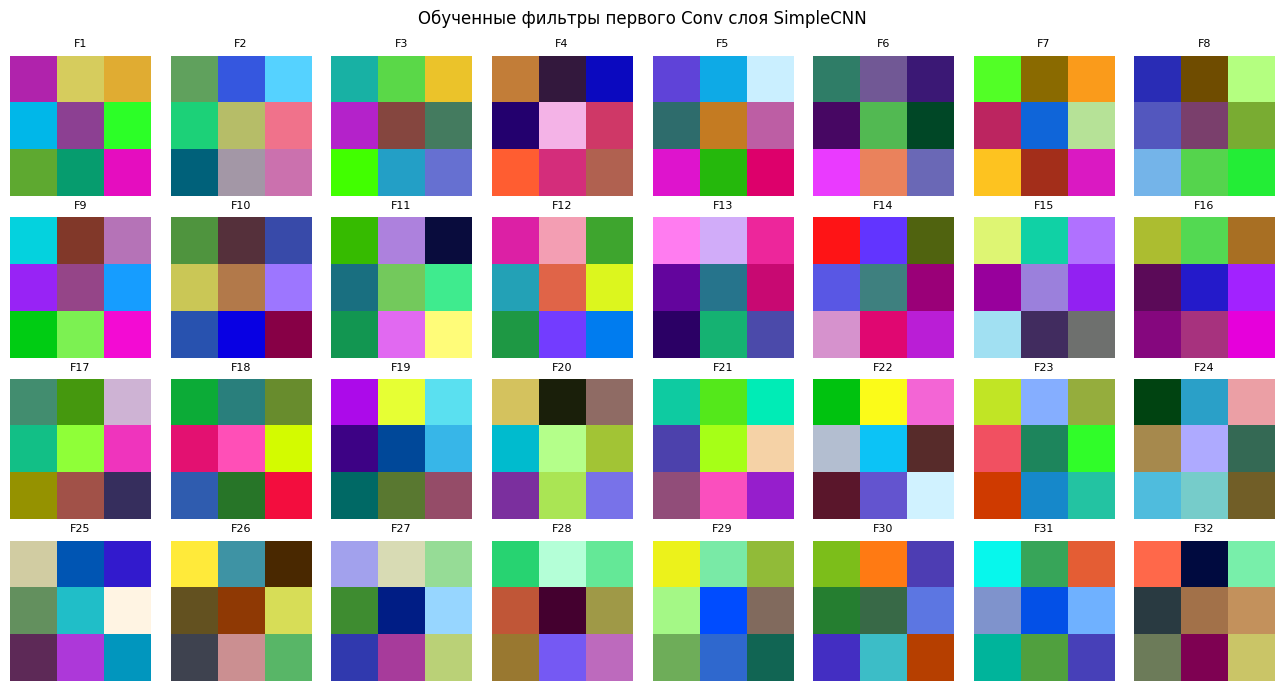

In [11]:
w=cnn.features[0][0].weight.detach().cpu()
fig,axes=plt.subplots(4,8,figsize=(13,7))
for i,ax in enumerate(axes.flat):
    fil=w[i].permute(1,2,0).numpy()
    fil=(fil-fil.min())/(fil.max()-fil.min()+1e-8)
    ax.imshow(fil);ax.set_title(f'F{i+1}',fontsize=8);ax.axis('off')
fig.suptitle('Обученные фильтры первого Conv слоя SimpleCNN')
plt.tight_layout();plt.savefig(OUTPUT/'06_filters.png',dpi=170);plt.show();plt.close(fig)



## 11. Feature maps

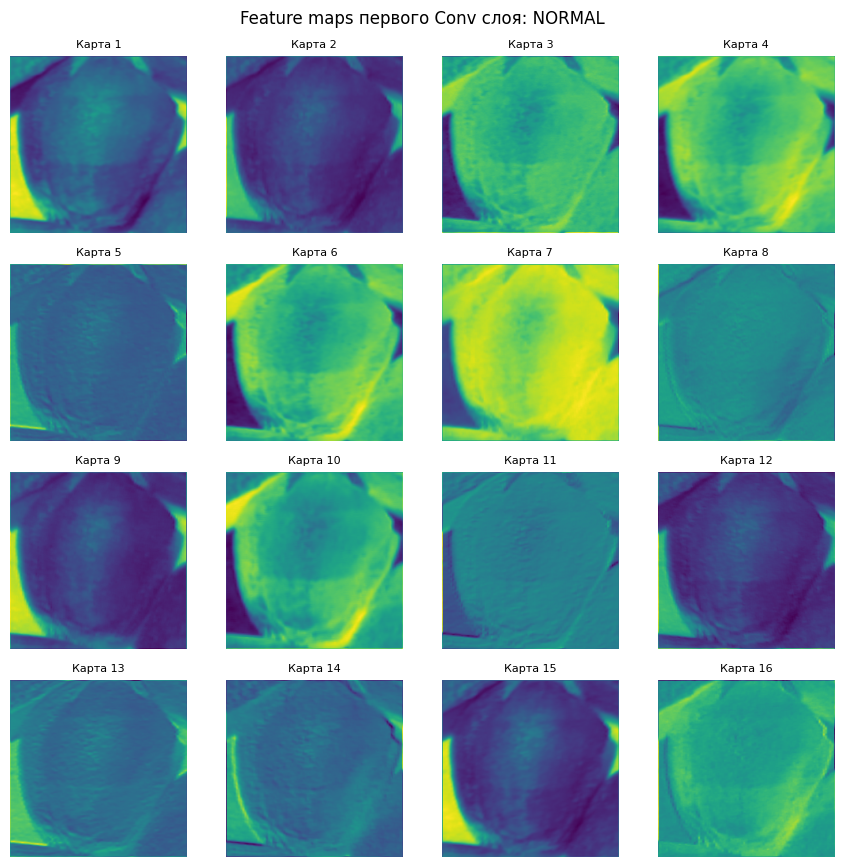

In [12]:
acts={}
def save_activations(module,inputs,out):acts['layer1']=out.detach()
handle=cnn.features[0][0].register_forward_hook(save_activations)
cnn.eval();im,label=val_dataset[0]
with torch.no_grad():_ = cnn(im.unsqueeze(0).to(device))
handle.remove()
feature_maps=acts['layer1'][0].cpu().numpy()
fig,axes=plt.subplots(4,4,figsize=(8.8,8.8))
for i,ax in enumerate(axes.flat):
    ax.imshow(feature_maps[i],cmap='viridis');ax.set_title(f'Карта {i+1}',fontsize=8);ax.axis('off')
fig.suptitle('Feature maps первого Conv слоя: '+CLASS_NAMES[label])
plt.tight_layout();plt.savefig(OUTPUT/'07_feature_maps.png',dpi=160);plt.show();plt.close(fig)



## 12. Grad-CAM для пяти зёрен с плесенью

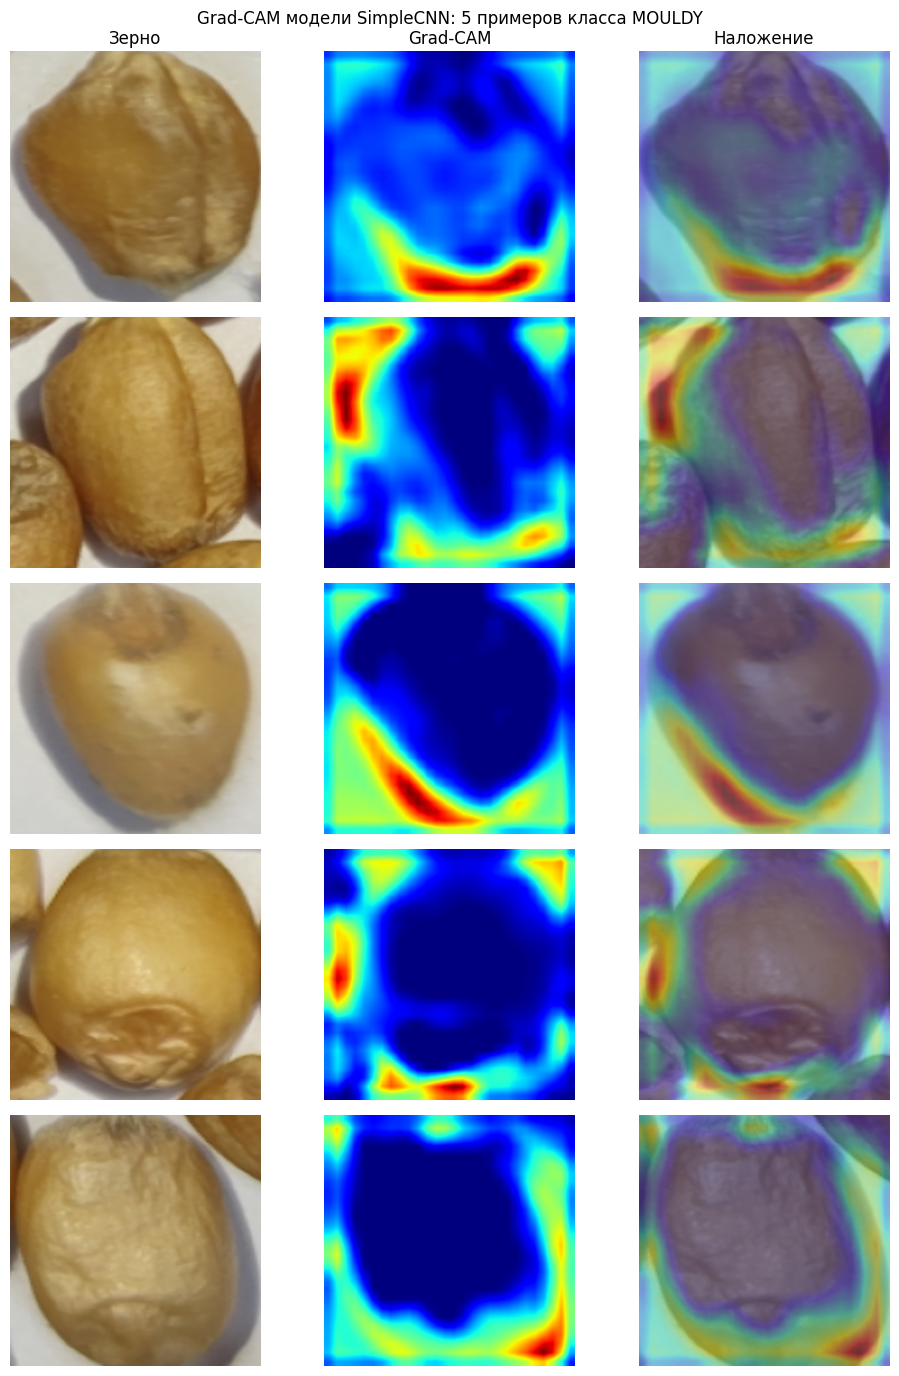

In [13]:
class GradCAM:
    def __init__(self,model,layer):
        self.model=model;self.activation=None;self.gradient=None
        self.handle=layer.register_forward_hook(self._save_activation)
    def _save_activation(self,module,inputs,output):
        self.activation=output.detach()
        output.register_hook(self._save_gradient)
    def _save_gradient(self,gradient):self.gradient=gradient.detach()
    def generate(self,x):
        self.model.eval();self.model.zero_grad(set_to_none=True)
        # logit относится именно к MOULDY=1, так что Grad-CAM объясняет вероятность плесени.
        score=self.model(x)[0,0]
        score.backward()
        weights=self.gradient.mean((2,3),keepdim=True)
        heat=F.relu((weights*self.activation).sum(dim=1,keepdim=True))
        heat=F.interpolate(heat,size=x.shape[-2:],mode='bilinear',align_corners=False)[0,0]
        heat=heat-heat.min();heat=heat/(heat.max()+1e-8)
        return heat.cpu().numpy()
    def close(self):self.handle.remove()

# Пять примеров класса MOULDY из валидационной выборки.
pos_ids=[i for i,(_,y) in enumerate(val_items) if y==1][:5]
if len(pos_ids)<5:raise ValueError('Нужно не менее 5 заплесневелых изображений в validation.')
# Grad-CAM для последнего свёрточного блока SimpleCNN.
cam_engine=GradCAM(cnn,cnn.features[3][0])
fig,axes=plt.subplots(5,3,figsize=(10,14))
for row,index in enumerate(pos_ids):
    im,_=val_dataset[index];x=im.unsqueeze(0).to(device)
    cam=cam_engine.generate(x)
    original=unnormalize(im)
    colormap=plt.get_cmap('jet')(cam)[:,:,:3]
    blend=np.clip(0.6*original+0.4*colormap,0,1)
    for ax,arr,title in zip(axes[row],[original,cam,blend],['Зерно','Grad-CAM','Наложение']):
        ax.imshow(arr,cmap='jet' if title=='Grad-CAM' else None);ax.axis('off')
        if row==0:ax.set_title(title)
cam_engine.close()
fig.suptitle('Grad-CAM модели SimpleCNN: 5 примеров класса MOULDY')
plt.tight_layout();plt.savefig(OUTPUT/'08_grad_cam.png',dpi=165);plt.show();plt.close(fig)



**Наблюдение по Grad-CAM.** На нескольких из пяти примеров MOULDY наиболее яркие области приходятся на края зёрен и фон. Поэтому визуализация сама по себе не доказывает, что SimpleCNN выделяет именно плесень; выводы следует проверять на дополнительных изображениях.


## 13. Data Augmentation

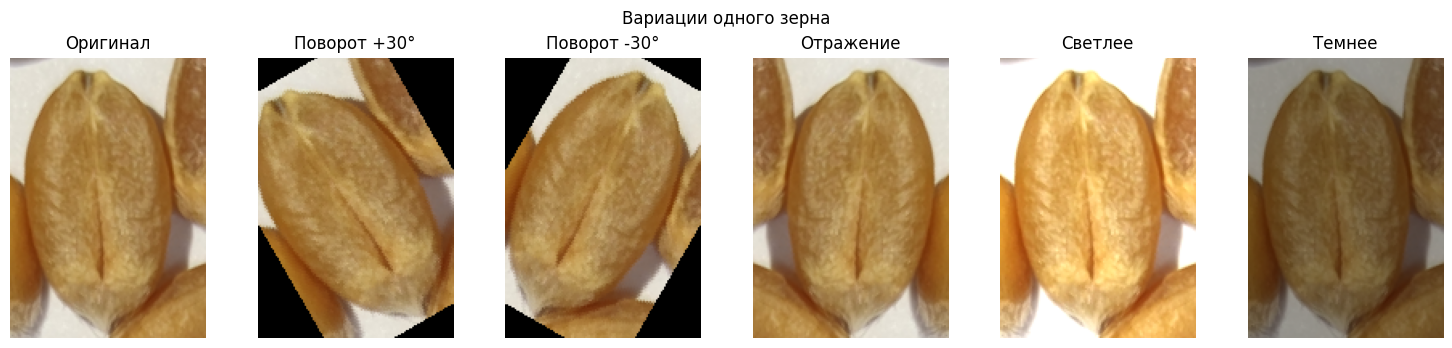

In [14]:
with Image.open(train_items[0][0]) as raw:raw=raw.convert('RGB')
augs=[('Оригинал',lambda z:z),('Поворот +30°',transforms.RandomRotation((30,30))),
      ('Поворот -30°',transforms.RandomRotation((-30,-30))),
      ('Отражение',transforms.RandomHorizontalFlip(p=1)),
      ('Светлее',transforms.ColorJitter(brightness=(1.35,1.35))),
      ('Темнее',transforms.ColorJitter(brightness=(.65,.65)))]
fig,axes=plt.subplots(1,6,figsize=(15,3.5))
for ax,(name,fn) in zip(axes,augs):
    ax.imshow(fn(raw));ax.set_title(name);ax.axis('off')
fig.suptitle('Вариации одного зерна')
plt.tight_layout();plt.savefig(OUTPUT/'09_augmentation.png',dpi=165);plt.show();plt.close(fig)



## 14. Скорость классификации одного зерна

In [15]:
def measure_single_image_seconds(net,ds,repeats=30):
    net.eval(); x=ds[0][0].unsqueeze(0).to(device)
    def sync():
        if device.type=='cuda':torch.cuda.synchronize()
    with torch.no_grad():
        for _ in range(5):_ = net(x)
        sync();durations=[]
        for _ in range(repeats):
            t0=perf_counter();_ = net(x);sync()
            durations.append(perf_counter()-t0)
    return float(np.median(durations))
latency=measure_single_image_seconds(best_model,test_dataset)
print(f'Медианное время обработки зерна: {latency:.4f} с на устройстве {device}')



Медианное время обработки зерна: 0.0043 с на устройстве cuda


## 15. Сохранение измеренных результатов

In [16]:
summary={
 'dataset':'GrainSpace / TRAIN-Wheat-M600',
 'n_train':len(train_items),'n_val':len(val_items),'n_test':len(test_items),
 'train_normal':Counter(l for _,l in train_items)[0],
 'train_mouldy':Counter(l for _,l in train_items)[1],
 'pos_weight':positive_weight,
 'class_names':CLASS_NAMES,
 'simple_params':cnn_params,'conv1_params':first_conv,'conv2_params':second_conv,
 'resnet_params':resnet_params,
 'cnn_best_val_acc':max(hist_cnn['val_acc']),'resnet_best_val_acc':max(hist_resnet['val_acc']),
 'cnn_seconds':time_cnn,'resnet_seconds':time_resnet,
 'cnn_epochs':len(hist_cnn['val_acc']),'resnet_epochs':len(hist_resnet['val_acc']),
 'cnn_last_gap':hist_cnn['train_acc'][-1]-hist_cnn['val_acc'][-1],
 'cnn_overfit_epoch':next((i+1 for i,(a,b) in enumerate(zip(hist_cnn['train_acc'],hist_cnn['val_acc'])) if a-b>=0.05),None),
 'best_name':best_name,
 'metrics':metrics,
 'confusion_matrix':cmat.tolist(),
 'inference_seconds':latency,
 'device':str(device),'torch_version':torch.__version__,
 'target_accuracy_pass':metrics['accuracy']>=.92,
 'target_speed_pass':latency<=.5,
 'train_max_normal':MAX_NORMAL,'train_max_mouldy':MAX_MOULDY,
}
with open(OUTPUT/'results.json','w',encoding='utf-8') as f:json.dump(summary,f,ensure_ascii=False,indent=2)
print('Результаты и все рисунки сохранены в',OUTPUT)


Результаты и все рисунки сохранены в /content/lr3_results


## 16. Формирование отчёта


In [17]:
!pip -q install python-docx

In [18]:
"""Формирование отчёта по ЛР № 3 на основе результатов экспериментов."""
from pathlib import Path
import sys,json
from docx import Document
from docx.shared import Cm,Pt,RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT,WD_CELL_VERTICAL_ALIGNMENT
from docx.enum.text import WD_BREAK
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.enum.style import WD_STYLE_TYPE

TOPIC='Свёрточные нейронные сети (CNN) для классификации изображений'
QUESTIONS=[
('1. Почему MLP плохо работает с изображениями?', 'Изображение приходится разворачивать в длинный вектор. Это создаёт большое число параметров, стирает информацию о расположении соседних пикселей и не позволяет естественно использовать один и тот же детектор признака в разных частях изображения.'),
('2. Как работает свёртка с фильтром 3×3?', 'Фильтр накладывается на участок 3×3, девять значений пикселей умножаются на девять весов ядра, результаты складываются и прибавляется смещение. Полученное число становится одним элементом карты признаков.'),
('3. Что такое feature map?', 'Карта признаков — пространственная карта откликов конкретного фильтра. Большой положительный отклик после активации означает, что в данной области сильно проявился изученный этим фильтром признак.'),
('4. Зачем нужен padding?', 'Padding добавляет пиксели на границах, позволяя свёртке сохранять размеры карты и учитывать край изображения. Без padding при ядре 3×3 и stride=1 каждая свёртка уменьшает высоту и ширину на 2; после 128 таких свёрток изображение размером 224×224 полностью исчезнет ещё до конца сети.'),
('5. Max Pooling или Average Pooling?', 'Max Pooling выбирает самый сильный отклик в окне, Average Pooling — средний. Для локальных пятен плесени Max Pooling полезен тем, что сохраняет ярко выраженные небольшие активации; окончательный выбор проверяется экспериментом.'),
('6. Что такое stride?', 'Stride — шаг перемещения фильтра. При stride=1 вычисляются отклики почти в каждой позиции, при stride=2 пространственные размеры обычно уменьшаются примерно вдвое.'),
('7. Зачем ResNet нужны skip connections?', 'Остаточные связи прибавляют вход блока к его преобразованному выходу. Благодаря этому градиенту легче проходить через глубокую сеть, а блок может обучать поправку к представлению, а не полное преобразование с нуля.'),
('8. Что такое transfer learning?', 'Перенос обучения — использование нейросети, ранее обученной на большом наборе изображений. Слои ResNet-18 уже распознают контуры, текстуры и формы, поэтому на меньшем наборе фотографий зёрен модели часто требуется меньше данных и времени для освоения нужных признаков.'),
('9. Какие аугментации безопасны для зерна?', 'Повороты и отражения обычно сохраняют диагноз зерна, так как ориентация несущественна. Умеренные изменения яркости тоже допустимы, но сильная цветокоррекция или обрезка могут скрыть налёт плесени. Случайный поворот на полный круг моделирует произвольную ориентацию зерна.'),
('10. Что показывает Grad-CAM?', 'Grad-CAM подсвечивает области карты признаков, наиболее влияющие на выбранный выходной балл сети. Для агронома это проверка, обращает ли модель внимание на поверхность зерна и характерные пятна, а не на фон. Карта объясняет решение приблизительно, но не доказывает его правильность.'),
('11. Почему BCEWithLogitsLoss?', 'BCEWithLogitsLoss объединяет сигмоиду и бинарную кросс-энтропию в численно устойчивой форме. Предварительно применять Sigmoid к выходу модели не нужно.'),
('12. Что будет без model.eval()?', 'Dropout продолжит случайно обнулять активации, а BatchNorm будет брать статистики текущего батча вместо накопленных. Это приведёт к нестабильным и некорректно сопоставимым результатам проверки.'),
('13. Стоит ли удваивать число фильтров при accuracy 93%?', 'Увеличатся потребление памяти, время вычислений, число параметров и риск переобучения. Нужно обучить исходную и расширенную модели на одинаковом разбиении и сравнить validation accuracy, recall, время инференса и матрицы ошибок; тестовую выборку использовать только после выбора.'),
('14. Почему recall важнее precision?', 'Ложноотрицательный ответ означает пропущенное заплесневелое зерно, что опасно для качества партии и здоровья посевов. Recall = TP/(TP+FN) показывает долю реально заплесневелых зёрен, обнаруженных системой. Высокая precision полезна, но недостаточная полнота ведёт к пропускам дефектов.')
]

def add_field(paragraph, name):
    r=paragraph.add_run();fld=OxmlElement('w:fldSimple');fld.set(qn('w:instr'),name);r._r.addnext(fld)

def label_value(d,label,value):
    p=d.add_paragraph();p.add_run(label+': ').bold=True;p.add_run(str(value))

def add_heading(d,txt,level=1):
    return d.add_heading(txt,level)

def add_figure(d,root,filename,caption,width=15.4,required=True):
    pth=root/filename
    if pth.exists():
        p=d.add_paragraph();p.alignment=WD_ALIGN_PARAGRAPH.CENTER
        r=p.add_run();r.add_picture(str(pth),width=Cm(width))
        cap=d.add_paragraph('Рисунок '+caption)
        cap.style='Caption';cap.alignment=WD_ALIGN_PARAGRAPH.CENTER
    elif required:
        p=d.add_paragraph('Рисунок '+caption+' — формируется после запуска ноутбука в Google Colab.');p.style='Placeholder'

def add_table(d,headers,rows,caption):
    p=d.add_paragraph(caption);p.style='TableCaption'
    t=d.add_table(rows=1,cols=len(headers));t.style='Table Grid';t.alignment=WD_TABLE_ALIGNMENT.CENTER
    for cell,name in zip(t.rows[0].cells,headers):
        cell.text=str(name)
        cell.vertical_alignment=WD_CELL_VERTICAL_ALIGNMENT.CENTER
        for r in cell.paragraphs[0].runs:r.bold=True
    for row in rows:
        cells=t.add_row().cells
        for c,v in zip(cells,row):
            c.text=str(v);c.vertical_alignment=WD_CELL_VERTICAL_ALIGNMENT.CENTER
    d.add_paragraph().paragraph_format.space_after=Pt(1)
    return t

def nfmt(v,digits=4):
    return f'{v:.{digits}f}' if isinstance(v,(int,float)) else 'после запуска Colab'

def write_report(summary=None,out_file='report_lab3.docx',result_dir=None):
    complete=summary is not None
    s=summary or {}
    folder=Path(result_dir) if result_dir else Path('.')
    d=Document();sec=d.sections[0]
    sec.page_height=Cm(29.7);sec.page_width=Cm(21)
    sec.left_margin=Cm(2.7);sec.right_margin=Cm(1.8)
    sec.top_margin=Cm(2);sec.bottom_margin=Cm(1.7)
    style=d.styles['Normal'];style.font.name='Times New Roman';style.font.size=Pt(12)
    style.paragraph_format.line_spacing=1.23
    style.paragraph_format.space_after=Pt(5)
    style.paragraph_format.first_line_indent=Cm(.72)
    for name in ['Title','Heading 1','Heading 2']:
        st=d.styles[name];st.font.name='Times New Roman';st.font.color.rgb=RGBColor(0,0,0)
    d.styles['Heading 1'].font.size=Pt(13);d.styles['Heading 1'].font.bold=True
    d.styles['Heading 1'].paragraph_format.space_before=Pt(10)
    d.styles['Heading 1'].paragraph_format.space_after=Pt(6)
    d.styles['Heading 2'].font.size=Pt(12);d.styles['Heading 2'].font.bold=True
    d.styles['Heading 2'].paragraph_format.space_before=Pt(8)
    d.styles['Heading 2'].paragraph_format.space_after=Pt(3)
    cap=d.styles['Caption'];cap.font.name='Times New Roman';cap.font.size=Pt(10);cap.font.color.rgb=RGBColor(0,0,0)
    cap.paragraph_format.first_line_indent=Cm(0);cap.paragraph_format.space_after=Pt(6)
    for nam in ['Placeholder','TableCaption']:
        if nam not in d.styles:st=d.styles.add_style(nam,WD_STYLE_TYPE.PARAGRAPH)
        else:st=d.styles[nam]
        st.font.name='Times New Roman';st.font.size=Pt(10)
        st.paragraph_format.first_line_indent=Cm(0);st.paragraph_format.space_before=Pt(4);st.paragraph_format.space_after=Pt(4)
        if nam=='Placeholder':st.font.italic=True;st.font.color.rgb=RGBColor(100,100,100)
    # Footer page numbers
    fp=sec.footer.paragraphs[0];fp.alignment=WD_ALIGN_PARAGRAPH.CENTER
    add_field(fp,'PAGE')
    # Cover
    for textval in ['МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ',
        'ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ БЮДЖЕТНОЕ',
        'УЧРЕЖДЕНИЕ ВЫСШЕГО ОБРАЗОВАНИЯ',
        '«ПОВОЛЖСКИЙ ГОСУДАРСТВЕННЫЙ ТЕХНОЛОГИЧЕСКИЙ УНИВЕРСИТЕТ»']:
        p=d.add_paragraph(textval);p.alignment=WD_ALIGN_PARAGRAPH.CENTER;p.paragraph_format.first_line_indent=Cm(0)
        p.paragraph_format.space_after=Pt(1)
        for r in p.runs:r.font.size=Pt(11);r.bold=True
    d.add_paragraph('\n\n\n')
    for tx in ['ОТЧЁТ ПО ЛАБОРАТОРНОЙ РАБОТЕ № 3',
               'по дисциплине «Машинное обучение и анализ данных»',
               'Тема: «'+TOPIC+'»']:
        p=d.add_paragraph(tx);p.alignment=WD_ALIGN_PARAGRAPH.CENTER
        p.paragraph_format.first_line_indent=Cm(0);p.paragraph_format.space_after=Pt(8)
        p.runs[0].bold=tx.startswith('ОТЧЁТ');p.runs[0].font.size=Pt(13 if tx.startswith('ОТЧЁТ') else 12)
    d.add_paragraph('\n\n')
    for tx in ['Выполнила: обучающаяся группы ИСТ-45','Ф. И. О.: Хазгалеева О.С.','Проверил: Танрывердиев И.О.']:
        p=d.add_paragraph(tx);p.alignment=WD_ALIGN_PARAGRAPH.RIGHT;p.paragraph_format.first_line_indent=Cm(0)
    d.add_paragraph('\n\n\n')
    for tx in ['Йошкар-Ола','2026']:
        p=d.add_paragraph(tx);p.alignment=WD_ALIGN_PARAGRAPH.CENTER;p.paragraph_format.first_line_indent=Cm(0)
    d.add_page_break()
    # Main
    add_heading(d,'Цель работы')
    d.add_paragraph('Изучить построение и обучение свёрточных нейронных сетей для анализа изображений зёрен пшеницы, сравнить SimpleCNN с предобученной ResNet-18, исследовать карты признаков и Grad-CAM, оценить качество обнаружения плесени по классификационным метрикам.')
    add_heading(d,'1. Данные и подготовка')
    d.add_paragraph('В работе используется набор GrainSpace, подмножество TRAIN-Wheat-M600. Исходные фотографии относятся к двум классам: NORMAL (здоровое зерно) и MOULDY (зерно с плесенью). Остальные категории пшеницы исключаются из бинарной постановки задачи. Изображения поступают из официального источника проекта GrainSpace; лицензия CC BY-NC-SA 4.0.')
    if complete:
        d.add_paragraph(f"Для эксперимента отобрано {s['n_train']+s['n_val']+s['n_test']} изображений (верхние ограничения отбора: NORMAL — до {s.get('train_max_normal')}, MOULDY — до {s.get('train_max_mouldy')}). "+
            f"Стратифицированное разделение с random_state=42: обучение — {s['n_train']}, валидация — {s['n_val']}, тест — {s['n_test']}. Тестовая выборка не участвовала в выборе модели. "+
            f"В train здоровых — {s['train_normal']}, заплесневелых — {s['train_mouldy']}; вес положительного класса pos_weight={s['pos_weight']:.3f}.")
    else:
        d.add_paragraph('Число исходных изображений, фактическое соотношение классов и размеры разделённых выборок определяются после загрузки архива и запуска кода. Планируемое разделение: train 70%, validation 15%, test 15% (seed = 42, стратификация). Отображаемый далее отчёт не содержит фиктивных измерений.')
    d.add_paragraph('Нормализация производится по статистикам ImageNet. Для train использованы повороты, отражения, обрезка с изменением масштаба и умеренные изменения яркости/контраста; validation и test преобразуются без случайных аугментаций. Положительный класс задан явно: NORMAL = 0, MOULDY = 1.')
    add_figure(d,folder,'01_samples.png','1 – Примеры зёрен классов NORMAL и MOULDY',width=13.1)
    add_heading(d,'2. Архитектура SimpleCNN')
    d.add_paragraph('Применена CNN с четырьмя блоками Conv2d(3×3, padding=1) → BatchNorm2d → ReLU → MaxPool2d(2). Число каналов последовательно составляет 32, 64, 128, 256. После AdaptiveAvgPool2d(1) используются Flatten, Dropout(0,5) и Linear(256,1). Сеть выдаёт логит положительного класса MOULDY; вероятность вычисляется через sigmoid.')
    add_table(d,['Слой','Характеристика'],[
      ['Вход','RGB, 3×224×224'],['Блок 1','Conv 3→32, BN, ReLU, Pool'],
      ['Блок 2','Conv 32→64, BN, ReLU, Pool'],['Блок 3','Conv 64→128, BN, ReLU, Pool'],
      ['Блок 4','Conv 128→256, BN, ReLU, Pool'],['Классификатор','AdaptiveAvgPool → Dropout 0,5 → Linear 1']
    ],'Таблица 1 – Архитектура SimpleCNN')
    if complete:
        d.add_paragraph(f"Число параметров первого свёрточного слоя: {s['conv1_params']}; второго: {s['conv2_params']}; общее число обучаемых параметров SimpleCNN: {s['simple_params']}. В MLP из ЛР № 2 было 235 146 параметров при входе 28×28; при росте разрешения число параметров первого полносвязного слоя резко увеличивается.")
    else:
        d.add_paragraph('У первого свёрточного слоя 896 параметров; у второго — 18 496. Общее число параметров автоматически выводится кодом. Для сравнения: MLP 784→256→128→10 из ЛР № 2 имела 235 146 параметров. Свёртки повторно используют одни и те же веса для всех позиций.')
    add_heading(d,'3. Обучение моделей и transfer learning')
    d.add_paragraph('SimpleCNN обучалась с BCEWithLogitsLoss, AdamW, CosineAnnealingLR, ранней остановкой по validation loss (patience=5). Вес положительного класса вычисляется по соотношению NORMAL/MOULDY на train; это реализует смысл pos_weight=3,0 из методики при соответствующем дисбалансе. Для ResNet-18 применены предобученные веса ImageNet, заменён последний слой на Linear(512,1), выполнено дообучение всех слоёв с меньшим шагом.')
    add_table(d,['Модель','Параметры','Best val accuracy','Время, с'],[
      ['SimpleCNN',nfmt(s.get('simple_params'),0),nfmt(s.get('cnn_best_val_acc')),nfmt(s.get('cnn_seconds'),1)],
      ['ResNet-18',nfmt(s.get('resnet_params'),0),nfmt(s.get('resnet_best_val_acc')),nfmt(s.get('resnet_seconds'),1)],
    ],'Таблица 2 – Сравнение SimpleCNN и ResNet-18')
    if complete:
        name=s['best_name'];d.add_paragraph(f"По наибольшей validation accuracy выбрана модель {name}. Модели обучались на одном разбиении данных, но с различными шагами оптимизатора. Transfer learning использует признаки, выученные ResNet-18 на ImageNet, и обычно ускоряет получение качественных представлений. Это не гарантирует победы ResNet на конкретной выборке: качество зависит от объёма, баланса и сходства доменов.")
        overfit=s.get('cnn_overfit_epoch')
        when=f'Начиная с {overfit}-й эпохи, разрыв не меньше 0,05.' if overfit else 'Разрыв 0,05 или выше за завершённые эпохи не выявлен.'
        d.add_paragraph(f"Последний разрыв train/val accuracy для SimpleCNN равен {s['cnn_last_gap']:.4f}. {when} Сильно положительное значение и рост val loss при падении train loss указывают на переобучение.")
    else:
        d.add_paragraph('После обучения следует определить, кто лидирует по validation accuracy, проверить разрыв train/val, записать время и сравнить устойчивость. Нельзя объявлять победителя без результатов реального запуска.')
    add_figure(d,folder,'02_cnn_learning.png','2 – Кривые обучения SimpleCNN',width=15.0)
    add_figure(d,folder,'03_resnet_learning.png','3 – Кривые обучения ResNet-18',width=15.0)
    add_heading(d,'4. Итоговая оценка качества')
    d.add_paragraph('Лучшая модель выбрана только по валидационной точности. Итоговые метрики рассчитываются на отложенной тестовой выборке, которую не использовали при обучении или настройке гиперпараметров. Порог вероятности для бинарной классификации равен 0,5.')
    add_table(d,['Метрика','Значение на test'],[
      ['Accuracy',nfmt(s.get('metrics',{}).get('accuracy'))],
      ['Precision для MOULDY',nfmt(s.get('metrics',{}).get('precision'))],
      ['Recall для MOULDY',nfmt(s.get('metrics',{}).get('recall'))],
      ['F1 для MOULDY',nfmt(s.get('metrics',{}).get('f1'))],
      ['BCE loss',nfmt(s.get('metrics',{}).get('loss'))],
      ['Медиана времени на зерно, с',nfmt(s.get('inference_seconds'),4)],
    ],'Таблица 3 – Результаты независимого тестирования')
    if complete:
        cm=s['confusion_matrix'];tp=cm[1][1];fn=cm[1][0];fp=cm[0][1]
        d.add_paragraph(f"Матрица ошибок: правильно обнаружено MOULDY {tp}, пропущено MOULDY {fn}, ошибочно помечено NORMAL как MOULDY {fp}. "+
         ('Цель accuracy ≥ 0,92 достигнута. ' if s['target_accuracy_pass'] else 'Цель accuracy ≥ 0,92 не достигнута. ')+
         ('Ограничение по времени ≤ 0,5 с соблюдено.' if s['target_speed_pass'] else 'Ограничение по времени ≤ 0,5 с не соблюдено.')+
         f" Измерения получены на устройстве {s['device']} и зависят от оборудования.")
    else:
        d.add_paragraph('Поля метрик и confusion matrix заполняются автоматически после выполнения обучения. Особое внимание следует уделить FN: пропускам плесневелых зёрен. Для задачи контроля качества зерна recall по MOULDY важнее, чем один лишь общий accuracy.')
    add_figure(d,folder,'04_best_learning.png','4 – Обучение лучшей модели',width=15.0)
    add_figure(d,folder,'05_confusion_matrix.png','5 – Матрица ошибок на test',width=12.0)
    add_heading(d,'5. Визуализация работы CNN')
    d.add_paragraph('Фильтры первого слоя SimpleCNN реагируют на оттенки, границы и текстуры зерна, а feature maps показывают пространственные отклики фильтров. На пяти изображениях MOULDY Grad-CAM SimpleCNN чаще выделяет края зёрен и прилегающий фон, а не только подозрительные пятна. Следовательно, эти карты пока не подтверждают, что модель выявляет плесень по нужным визуальным признакам; для практического применения потребуется дополнительная проверка.')
    add_figure(d,folder,'06_filters.png','6 – Фильтры первого свёрточного слоя',width=15.0)
    add_figure(d,folder,'07_feature_maps.png','7 – Feature maps первого свёрточного слоя',width=12.2)
    add_figure(d,folder,'08_grad_cam.png','8 – Grad-CAM для пяти изображений класса MOULDY',width=12.3)
    add_heading(d,'6. Влияние аугментации')
    d.add_paragraph('Применялись случайные повороты и отражения, изменение масштаба, небольшие изменения яркости и контраста. Это позволяет использовать одну и ту же метку при разных положениях зерна. Слишком сильная цветокоррекция, размывание и обрезка могут скрыть характерные пятна и нарушить смысл изображения.')
    add_figure(d,folder,'09_augmentation.png','9 – Шесть вариантов одного изображения зерна',width=15)
    add_heading(d,'Выводы')
    d.add_paragraph('1. Построена архитектура SimpleCNN с четырьмя свёрточными блоками и бинарным классификатором; реализовано обучение с валидацией и ранней остановкой.')
    d.add_paragraph('2. Для сопоставления реализован transfer learning ResNet-18 с заменённой классификационной головой и дообучением всех параметров.')
    if complete:
        d.add_paragraph(f"3. По валидации выбрана {s['best_name']}; на независимом тесте accuracy = {s['metrics']['accuracy']:.4f}, recall для MOULDY = {s['metrics']['recall']:.4f}, F1 = {s['metrics']['f1']:.4f}.")
    else:d.add_paragraph('3. Сопоставление точности CNN и ResNet-18 и проверка порога 92% выполняются по фактическим результатам запуска ноутбука.')
    d.add_paragraph('4. Визуализации фильтров, feature maps и Grad-CAM получены. На части карт выделены контуры зерна и фон, поэтому интерпретация выводов требует дополнительной проверки.')
    d.add_paragraph('5. При оценке пригодности к использованию следует отдельно контролировать полноту распознавания плесени, скорость и качество на изображениях из других условий съёмки.')
    add_heading(d,'Ответы на контрольные вопросы')
    for q,a in QUESTIONS:
        p=d.add_paragraph();p.paragraph_format.first_line_indent=Cm(0)
        rr=p.add_run(q+' ');rr.bold=True;p.add_run(a)
    add_heading(d,'Использованные источники')
    for item in [
        '1. Umbratick. Лабораторная работа № 3 «Свёрточные нейронные сети (CNN) для классификации изображений». https://github.com/umbratick/ml-da/blob/main/sem2/lab3.md',
        '2. Fan L. et al. GrainSpace: A Large-Scale Dataset for Fine-Grained and Domain-Adaptive Recognition of Cereal Grains. CVPR, 2022. https://grainnet.github.io/GrainSpace.html',
        '3. PyTorch Documentation. https://pytorch.org/docs/stable/',
        '4. He K. et al. Deep Residual Learning for Image Recognition. 2015. https://arxiv.org/abs/1512.03385',
        '5. Selvaraju R. R. et al. Grad-CAM: Visual Explanations from Deep Networks. 2017. https://arxiv.org/abs/1610.02391'
    ]:
        p=d.add_paragraph(item);p.paragraph_format.first_line_indent=Cm(0)
    add_heading(d,'Приложение А. Программная реализация')
    d.add_paragraph('Полный листинг реализации и исполняемый вариант анализа приведены в прилагаемом файле «ЛР3_CNN_GrainSpace_Colab.ipynb». Код включает загрузку GrainSpace, обучение, визуализации и автоматическое формирование отчёта.')
    if not complete:
        p=d.add_paragraph('ПРИМЕЧАНИЕ: это подготовленный отчёт. Иллюстрации экспериментов и числовые результаты автоматически появятся после запуска ноутбука на реальных изображениях GrainSpace.');p.style='Placeholder'
    d.save(str(out_file))
    return out_file



In [19]:
from pathlib import Path
import json
final_results_dir = OUTPUT
with open(final_results_dir/'results.json',encoding='utf-8') as f:
    measured = json.load(f)
final_docx = final_results_dir/'Отчет_ЛР3_CNN_GrainSpace.docx'
write_report(measured,final_docx,final_results_dir)
print('Отчёт готов:',final_docx)
try:
    from google.colab import files
    files.download(str(final_docx))
except ImportError:
    print('Файл отчёта находится здесь:',final_docx)


Отчёт готов: /content/lr3_results/Отчет_ЛР3_CNN_GrainSpace.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>